# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AxelYoel/FlyRank-AI-Internship---Axel-Yoel-Chandra/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

**The queue.** Pages are ranked by February lost clicks: (typical click rate for the
page's position tier x February impressions) - February clicks. A bigger gap ranks
higher.

**Why this method.** I use the carry-forward rule because it is simple, needs no training
or train/test split, and a manager can read it in one sentence. In W05 it tied with
Linear Regression as the best method I tested (precision@20 0.43 vs 0.41 at 5 folds;
0.39 vs 0.395 at 10 folds), so the simpler method wins. Its weaknesses: it cannot rank
the pages with no February data, and it uses click rates computed from March. I tested
that leak for the model in W06 but not for this rule. I also never checked whether the
model works where the rule cannot be applied.

**Action for a ranked page:** `review_low_clicks_for_position`. The reviewer checks the
page using the section 3 checklist. The label means "this page got fewer clicks than
typical for its position". It does not mean the clicks can be recovered.

**Reason codes**
- `feb_gap_vs_tier_rate`: ranked; fewer February clicks than the typical page at its position.
- `no_prior_month_data`: not ranked, because there is no usable February traffic. Split
  into not_yet_created, new_page (under 60 days old) and older_page (see section 3).

**What the queue is worth (cost/value).** If a reviewer can only look at 100 pages, the
queue's top 100 held about 10% of the clicks lost in March across 33,950 ranked pages,
against about 0.3% expected for 100 random pages and about 15% for the best possible 100
chosen with hindsight. Precision@20 against that month's true top 20 was 0.40. The queue
is far better than random and reaches about two-thirds of that ceiling. Shares count only
pages that got fewer clicks than expected.

The cost of review is the reviewer's time. I assume 30 minutes per page (a guess, not
measured), so reviewing 20 pages takes about 10 hours and 100 pages about 50 hours.

**Limits of this evidence:** one month; March click rates were used to define lost
clicks (a small leak); lost clicks are not recovered clicks; June 2026 was not used.

In [1]:
import os, json
import duckdb
import numpy as np
import pandas as pd
from google.colab import userdata

In [3]:
hf_token = userdata.get("HF_token")
os.environ["HF_token"] = hf_token
con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{hf_token}')")
rel = "hf://datasets/FlyRank/internship-warehouse"

In [4]:
REVIEW_DATE = pd.Timestamp('2026-02-28')   # the date the queue is "run": February complete, March not started
NEW_DAYS = 60                               # new_page cutoff in days (initial guess, see section 3)
metrics = {}

In [5]:
# ---- Build the queue: March population + February score ----
base = con.sql(f"""
    WITH daily AS (
        SELECT content_hash_id, gsc_impressions, gsc_clicks
        FROM read_parquet('{rel}/fact_content_daily_performance/month=2026-03/data_0.parquet')
        WHERE gsc_data_available = TRUE AND gsc_avg_position > 0 AND gsc_impressions > 0
    ),
    rollup AS (
        SELECT content_hash_id, SUM(gsc_impressions) AS mar_impressions
        FROM daily GROUP BY content_hash_id
        HAVING SUM(gsc_impressions) >= 50
    )
    SELECT r.content_hash_id, r.mar_impressions,
           c.client_hash_id, c.search_volume, c.content_created_date
    FROM rollup r
    JOIN read_parquet('{rel}/dim_content.parquet') c USING (content_hash_id)
    WHERE c.content_type = 'keyword article' AND c.search_volume >= 20
""").df()

feb = con.sql(f"""
    WITH daily AS (
        SELECT content_hash_id, gsc_avg_position, gsc_impressions, gsc_clicks
        FROM read_parquet('{rel}/fact_content_daily_performance/month=2026-02/data_0.parquet')
        WHERE gsc_data_available = TRUE AND gsc_avg_position > 0 AND gsc_impressions > 0
    )
    SELECT content_hash_id,
           SUM(gsc_impressions) AS feb_impressions,
           SUM(gsc_clicks) AS feb_clicks,
           SUM(gsc_avg_position * gsc_impressions) / SUM(gsc_impressions) AS feb_position
    FROM daily GROUP BY content_hash_id
""").df()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [6]:
q = base.merge(feb, on='content_hash_id', how='left')
q['has_feb'] = q['feb_impressions'].notna()

q['feb_expected_ctr'] = np.select(
    [q['feb_position'] <= 3, q['feb_position'] <= 10, q['feb_position'] <= 20],
    [0.002811, 0.002353, 0.002226], default=0.000748)
q['feb_lost_clicks'] = np.where(
    q['has_feb'], q['feb_expected_ctr'] * q['feb_impressions'] - q['feb_clicks'], np.nan)

In [7]:
# rank only pages that have February data
q['rank'] = q['feb_lost_clicks'].rank(ascending=False, method='first')

In [8]:
# reason codes, groups, action label, reviewer note
created = pd.to_datetime(q['content_created_date'])
age_days = (REVIEW_DATE - created).dt.days
q['reason_code'] = np.where(q['has_feb'], 'feb_gap_vs_tier_rate', 'no_prior_month_data')
q['unranked_group'] = np.select(
    [q['has_feb'], age_days < 0, age_days < NEW_DAYS],
    ['ranked', 'not_yet_created', 'new_page'], default='older_page')
q['action_label'] = np.where(q['has_feb'], 'review_low_clicks_for_position', None)
q['review_note'] = q['unranked_group'].map({
    'ranked': 'review in rank order',
    'new_page': 're-check next month',
    'older_page': 'reserve ~20% of review time, highest search volume first',
    'not_yet_created': 'testing only: page did not exist at review date'})

print("share with no Feb data:", round((~q['has_feb']).mean(), 3), "(W05 said 0.123)")
print(q['unranked_group'].value_counts())

metrics.update(
    review_date=str(REVIEW_DATE.date()),
    n_pages=int(len(q)),
    group_counts=q['unranked_group'].value_counts().to_dict(),
    older_page_share=round(float((q['unranked_group'] == 'older_page').mean()), 4),
    new_page_days_cutoff=NEW_DAYS,
)

share with no Feb data: 0.123 (W05 said 0.123)
unranked_group
ranked             33950
not_yet_created     2639
new_page            1674
older_page           463
Name: count, dtype: int64


In [9]:
# ---- Cost/value: how many of March's lost clicks sit in the queue's top 100? ----
mar = con.sql(f"""
    WITH daily AS (
        SELECT content_hash_id, gsc_avg_position, gsc_impressions, gsc_clicks
        FROM read_parquet('{rel}/fact_content_daily_performance/month=2026-03/data_0.parquet')
        WHERE gsc_data_available = TRUE AND gsc_avg_position > 0 AND gsc_impressions > 0
    )
    SELECT content_hash_id,
           SUM(gsc_clicks) AS mar_clicks,
           SUM(gsc_avg_position * gsc_impressions) / SUM(gsc_impressions) AS mar_position
    FROM daily GROUP BY content_hash_id
""").df()

r = q[q['unranked_group'] == 'ranked'].merge(mar, on='content_hash_id', how='left')
r['mar_expected_ctr'] = np.select(
    [r['mar_position'] <= 3, r['mar_position'] <= 10, r['mar_position'] <= 20],
    [0.002811, 0.002353, 0.002226], default=0.000748)
r['mar_lost'] = r['mar_expected_ctr'] * r['mar_impressions'] - r['mar_clicks']

pos = r['mar_lost'].clip(lower=0)
def share(ids):
    return float(pos[r['content_hash_id'].isin(ids)].sum() / pos.sum())

K = 100
cost_value = {
    'k': K,
    'n_ranked_pages': int(len(r)),
    'queue_top_k_share': round(share(r.nsmallest(K, 'rank')['content_hash_id']), 3),
    'best_possible_top_k_share': round(share(r.nlargest(K, 'mar_lost')['content_hash_id']), 3),
    'random_k_share_expected': round(K / len(r), 4),
}
top20_queue = set(r.nsmallest(20, 'rank')['content_hash_id'])
top20_best = set(r.nlargest(20, 'mar_lost')['content_hash_id'])
cost_value['queue_precision_at_20'] = len(top20_queue & top20_best) / 20
metrics['cost_value'] = cost_value
print(cost_value)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{'k': 100, 'n_ranked_pages': 33950, 'queue_top_k_share': 0.102, 'best_possible_top_k_share': 0.154, 'random_k_share_expected': 0.0029, 'queue_precision_at_20': 0.4}


## 2. Intended use and limits

**Who uses it, and for what.** A content strategist or SEO analyst, once a month, to
decide which pages to look at first. It is decision support: it points to pages whose
clicks were low for their position. It does not say why, and it does not show that any
change would raise traffic.

**What it covers.** Keyword articles with search volume of 20 or more and at least 50
impressions in March 2026: 38,726 pages across 43 clients. The queue ranks the 33,950
pages with usable February data, from 36 clients. The other 7 clients (121 pages) have no
ranked pages: their search data starts between Feb 19 and Mar 27, 2026 (five of them
after Feb 28), and 114 of their 121 pages were created after Feb 28. June 2026 was not
used.

**Where it stops being valid:**
- Other content types (comparison and feedly articles are not scored).
- New clients, or clients whose search data starts after the review date, until they
  have a full month of history.
- Pages with no February data: these are not ranked (section 3).
- A different month or a different portfolio, until the section 4 checks have been run.

**Known weaknesses:**
- Expected click rates are close together across positions 1 to 20 in this data, so the
  queue mostly flags pages with many impressions and few clicks. Pages with zero or very
  few clicks pull the typical (median) rate below the pooled rate.
- The click rates used to define lost clicks come from March (a small leak: W06 tested it
  for the model, not for this rule).
- Search volume and competition come from a snapshot with no date of its own.
- Results rest on one month. In W05, precision@20 for this rule varied from 0.25 to 0.55
  across 5 folds, and from 0.10 to 0.70 across 10 folds.
- The top 5 clients hold about 82% of the ranked pages (36 clients in total), so the
  queue's results mostly reflect a few large clients. Per-client results were not checked.

**What the data did not show (decay/refresh).** I expected old, un-updated pages to lose
more clicks. The data did not show a clear pattern: the W04 check was mixed (the 91 to
365 day group had only 208 pages), days since update had near-zero weight in the W05
model, and recomputing it as of February 28 changed 63 of 5,132 pages with identical
scores. This queue therefore makes no refresh recommendation.

**Not built.** I did not build content archetypes. This work stayed on one question,
which pages to review first, and the evidence for grouping pages by type was not tested.
An archetype-to-action mapping is left as future work.

**Not claimed:** that pages on the queue will gain clicks if edited, or why a page's
traffic was low.

In [10]:
rk = q[q['unranked_group'] == 'ranked']
n_clients_all, n_clients_ranked = q['client_hash_id'].nunique(), rk['client_hash_id'].nunique()
top5_share = rk['client_hash_id'].value_counts().head(5).sum() / len(rk)
print(n_clients_all, n_clients_ranked, round(top5_share, 3))
metrics.update(n_clients_all=int(n_clients_all), n_clients_ranked=int(n_clients_ranked),
               top5_client_share_ranked=round(float(top5_share), 3))

# why do some clients have no ranked pages? (client ids are not printed)
missing = sorted(set(q['client_hash_id']) - set(q.loc[q['has_feb'], 'client_hash_id']))
sub = q[q['client_hash_id'].isin(missing)]
print(len(missing), "clients,", len(sub), "pages")
print(sub.groupby('client_hash_id')['unranked_group'].value_counts().unstack(fill_value=0)
         .reset_index(drop=True))

starts = con.sql(f"""
    SELECT client_hash_id, gsc_data_start
    FROM read_parquet('{rel}/dim_clients.parquet')
""").df()
print(starts[starts['client_hash_id'].isin(missing)]['gsc_data_start'].sort_values().tolist())

43 36 0.816
7 clients, 121 pages
unranked_group  new_page  not_yet_created
0                      0                6
1                      0               11
2                      5               16
3                      1                0
4                      1               78
5                      0                2
6                      0                1
[Timestamp('2026-02-19 00:00:00'), Timestamp('2026-02-26 00:00:00'), Timestamp('2026-03-11 00:00:00'), Timestamp('2026-03-12 00:00:00'), Timestamp('2026-03-19 00:00:00'), Timestamp('2026-03-25 00:00:00'), Timestamp('2026-03-27 00:00:00')]


## 3. Human review + the no-go list

**Who reviews and how it's used.** A content strategist or SEO analyst looks at each
queued page before anything is changed. The queue says where to look first. It does not
say what is wrong with a page or what change would work.

**Before acting on a page, answer these yes/no questions:**

1. **Technical problem?** Is the page indexed and crawled? Was its URL or structure
   recently changed? If yes: sort that out first, since a content edit may not help.
2. **Intent mismatch?** Does the page match what people searching its keyword want to
   see? If no: record it as a possible reason, to be tested, not as the cause.
3. **Sharp traffic change since February?** If yes: the queue ranks by February traffic,
   so this page's rank may be unreliable. Note the page and re-check it next month, even
   if it is no longer on the list.
4. **Crossed a position tier?** Moves between tiers 1 to 3 change the expected click rate
   only slightly. Moving into or out of 21+ changes it about three to four times (March
   rates). If the page crossed the 21+ boundary: check its current position, recompute
   the gap with its current tier's rate, and lower its priority if the gap disappears.
5. **No February data?** These pages are not ranked, because the queue's score needs
   last month's traffic. They carry the reason code `no_prior_month_data` and sit in a
   separate list, split in two:
   - **New pages** (created fewer than 60 days before the review date, initial guess):
     too early to judge. Note them and re-check next month, when they have a month of
     data and can enter the ranked queue.
   - **Older pages with no February data:** the reviewer reserves about 20% of review
     time (initial guess) for these, highest search volume first. Search volume is a
     topic-level number with no date of its own, so it only sets what to look at first.
   No February data does not mean no problem; these pages were not checked.
6. **Competing pages?** Several pages can share one search volume number, so two queued
   pages may be competing for the same topic. If yes: review them together and decide
   which one to work on.

**Should never be automated:**
- publishing edits to a page
- deleting or merging pages
- telling a client what a change will achieve ("will increase", "recovers clicks")
- using the queue on other content types or new clients without re-checking it

**Why the 60-day cutoff.** At 20, 30 and 60 days the older-page list had 1,272, 783 and
463 pages. I chose 60 so that the list is smaller and each page can get more reviewer
time. The cost is that pages 20 to 60 days old wait longer. The data cannot say how long
a page needs to settle, so the cutoff is a judgment.

**Why these limits.** This is observational data from one month, for keyword articles
only (see section 2). The queue flags pages with fewer clicks than the typical page at
their position. It does not show that any change would raise traffic, or why a page's
traffic fell.

In [11]:
# how the older-page list changes with the "new page" cutoff
cutoff_table = {}
for d in [20, 30, 60]:
    g = np.select([q['has_feb'], age_days < 0, age_days < d],
                  ['ranked', 'not_yet_created', 'new_page'], default='older_page')
    cutoff_table[d] = pd.Series(g).value_counts().to_dict()
metrics['cutoff_sensitivity'] = cutoff_table
print(cutoff_table)

{20: {'ranked': 33950, 'not_yet_created': 2639, 'older_page': 1272, 'new_page': 865}, 30: {'ranked': 33950, 'not_yet_created': 2639, 'new_page': 1354, 'older_page': 783}, 60: {'ranked': 33950, 'not_yet_created': 2639, 'new_page': 1674, 'older_page': 463}}


## 4. Monitoring / retrain triggers

Run each month on the new month's data, computed the same way as today's baseline.
Thresholds are starting guesses from one month of data, to be revisited.

| Watch this | Now | Worry if |
|---|---|---|
| Precision@20 vs that month's true top 20 | 0.40 | 0.30 or lower for 3 months in a row |
| Older-page share (60-day cutoff) | 1.2% (463 of 38,726) | reaches 2% |
| Typical click rate per position tier | 0.2811%, 0.2353%, 0.2226%, 0.0748% (March) | any rate differs by more than 25% |

**Why 25%:** in a test scaling all four rates together, a 10% change kept 93 to 94 of the
top 100 pages and a 25% change kept 81 to 85. One rate moving alone was not tested.

**If a trigger fires:** the queue is paused first. The person running the monthly check
tells the reviewer, then checks which trigger fired and follows the matching first step:
compare the queue with a Linear Regression list, check created dates, or recompute the
four rates. The queue resumes only after a person approves it, either unchanged or
rebuilt. Nothing is retrained or changed automatically. Pausing stops review work even
for a minor trigger, which is a cost of choosing the cautious option.

**Limits:** the older-page share depends on the 60-day cutoff and on how much a client
publishes. "Retrain" here means recomputing four rates and rebuilding a rule, since no
model is trained.

In [12]:
f = q[q['has_feb']].copy()
base_rates = np.array([0.002811, 0.002353, 0.002226, 0.000748])
tier_idx = np.select([f['feb_position'] <= 3, f['feb_position'] <= 10,
                      f['feb_position'] <= 20], [0, 1, 2], default=3)

def top_ids(scale):
    lost = base_rates[tier_idx] * scale * f['feb_impressions'] - f['feb_clicks']
    return set(f.loc[lost.nlargest(100).index, 'content_hash_id'])

base_top = top_ids(1.0)
sens = {s: len(base_top & top_ids(s)) for s in [0.75, 0.9, 1.1, 1.25]}
print(sens)   # how many of the baseline top 100 survive
metrics['rate_sensitivity_top100_overlap'] = sens

{0.75: 81, 0.9: 94, 1.1: 93, 1.25: 85}


## 5. Exports for the paper

The cell below writes:
- `work/outputs/action_queue.csv`: the ranked queue with reason codes and action labels.
  Pages that did not exist at the review date (not_yet_created) are left out. This file
  stays out of git by design; this notebook regenerates it.
- `work/outputs/queue_metrics.json`: the numbers the paper can trace back to (group
  counts, cost/value shares, cutoff comparison, rate sensitivity, client counts).
- `work/figures/queue_value_top100.png`: share of March's lost clicks held by 100 random
  pages, the queue's top 100, and the best possible 100. This figure is committed.

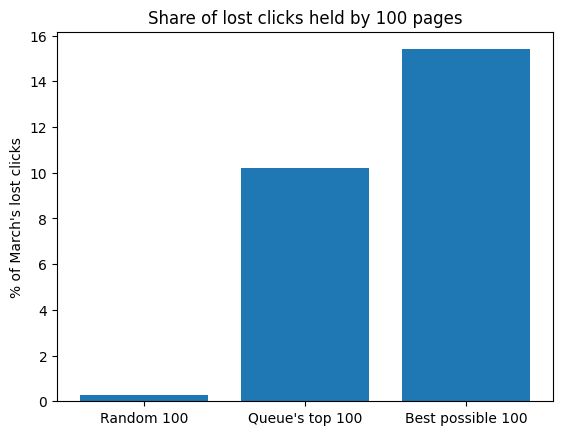

36087 rows written to work/outputs/action_queue.csv


In [13]:
import matplotlib.pyplot as plt
os.makedirs('work/outputs', exist_ok=True); os.makedirs('work/figures', exist_ok=True)

out = q[q['unranked_group'] != 'not_yet_created']   # testing-only group left out
cols = ['rank', 'content_hash_id', 'action_label', 'reason_code', 'unranked_group',
        'review_note', 'feb_lost_clicks', 'feb_impressions', 'feb_clicks', 'search_volume']
out.sort_values(['rank', 'search_volume'], ascending=[True, False], na_position='last')[cols] \
   .to_csv('work/outputs/action_queue.csv', index=False)

with open('work/outputs/queue_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2, default=str)

v = [cost_value['random_k_share_expected'], cost_value['queue_top_k_share'],
     cost_value['best_possible_top_k_share']]
plt.bar(['Random 100', "Queue's top 100", 'Best possible 100'], [x * 100 for x in v])
plt.ylabel("% of March's lost clicks"); plt.title('Share of lost clicks held by 100 pages')
plt.savefig('work/figures/queue_value_top100.png', dpi=150, bbox_inches='tight')
plt.show()
print(len(out), "rows written to work/outputs/action_queue.csv")

## Self-check

Before you submit, confirm each line honestly:

- [Done] Every section above is filled — markdown thinking AND the code that backs it
- [Done] The notebook runs top to bottom with no errors (Runtime → Run all)
- [Done] No client names, URLs, or private queries anywhere
- [Done] My claims use careful words: observed, measured, directional, decision-support
- [Done] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.